# One Model On All The Data with `ShardedModel`

In the [`fit_grouped` tutorial](grouped_tutorial.ipynb) we estimated each store's price elasticity by fitting every store on its own. A store with only a few days of data then gets a vague, noisy estimate.

A *hierarchical* (multilevel) model does better. It fits all stores together, where each store still gets its own elasticity, but the elasticities are assumed to come from one shared distribution, whose center and spread the model learns from all the stores. A store with little data borrows strength from the others.

That is **one** model on **all** the data. With a lot of data, sampling becomes slow because every step of the sampler evaluates the model on every row. `pymc_ray.ShardedModel` spreads that work over [Ray](https://www.ray.io) workers:

1. The rows are split into *shards*, and each shard is held by its own Ray worker for the whole run.

2. PyMC's sampler runs in this notebook as usual. At every step it sends the current parameter values to the workers. Each worker computes the log-likelihood of its own rows, and its gradient, and the results are added up.

3. The sum is the log-likelihood of all the data, so the posterior is **exact**, the same as one `pm.sample` gives on all the data. That is why `ShardedModel` works for hierarchical models, unlike `consensus_sample`.

In this notebook we simulate some data, write the model, measure whether sharding pays off, sample, and check the results, with a posterior predictive check and LOO.

Note
----
The price of exactness is communication: at every step, the sampler waits for every worker. That pays off when each step has a lot of rows to work through. On small data, plain `pm.sample` is faster.

In [1]:
import os

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import ray

import pymc_ray as pmr

plt.rcParams.update(
    {
        "figure.figsize": (14, 4),
        "figure.dpi": 144,
        "figure.facecolor": "w",
        "axes.grid": True,
        "grid.linewidth": 0.5,
        "grid.linestyle": "--",
        "axes.spines.top": False,
        "axes.spines.bottom": False,
        "axes.spines.left": False,
        "axes.spines.right": False,
        "figure.constrained_layout.use": True,
    }
)

## Start Ray

`ray.init()` starts Ray on this machine and uses all of its CPUs. `log_to_driver=False` keeps the workers' logs out of the notebook.

To use a cluster instead, set the `RAY_ADDRESS` environment variable to the cluster's [Ray Client](https://docs.ray.io/en/latest/cluster/running-applications/job-submission/ray-client.html) address (for example `ray://localhost:10001`) before starting Jupyter. `runtime_env` then installs this notebook's PyMC version on the cluster and copies `pymc_ray` there. The sampler then runs on the cluster too, next to the shards (see below).

In [2]:
ray_address = os.environ.get("RAY_ADDRESS")  # None: start Ray on this machine
runtime_env = (
    {
        "pip": [f"pymc=={pm.__version__}", "narwhals>=2", "matplotlib"],
        "py_modules": [os.path.dirname(pmr.__file__)],
        "env_vars": {
            "TTY_COMPATIBLE": "1",
            "COLUMNS": "120",
            "RAY_get_check_signal_interval_milliseconds": "10",
            "RAY_max_direct_call_object_size": "8388608",
        },
    }
    if ray_address
    else None
)

ray.init(address=ray_address, runtime_env=runtime_env, log_to_driver=False)
print(f"Ray is using {ray.cluster_resources()['CPU']:.0f} CPUs")

2026-10-29 11:10:20,463	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html
2026-10-29 11:10:23,512	INFO worker.py:2024 -- Started a local Ray instance. View the dashboard at http://127.0.0.1:8265 


Ray is using 14 CPUs


## Simulate some data

Each row is one day of sales in one store, on the log scale as in the `fit_grouped` tutorial. Each store gets its own baseline sales and its own elasticity. The elasticities come from a normal distribution with mean -1.5 and standard deviation 0.4, which the model should recover.

The stores opened at different times, where some have two years of data, and many only a few weeks or days. The stores with little data are where the hierarchical model helps most.

In [3]:
rng = np.random.default_rng(0)
n_stores = 1_000
# n_stores = 50_000 # uncomment if you are running on a real cluster to see real performance gains
stores = [f"store_{i:04d}" for i in range(n_stores)]

# The true values, named like the model's parameters below
true_mu_elasticity = -1.5
true_sigma_elasticity = 0.4
true_sigma = 0.3

true_elasticity = pd.Series(rng.normal(true_mu_elasticity, true_sigma_elasticity, n_stores), index=stores)
baseline = rng.normal(5.0, 0.5, n_stores)

# Days of data per store, from a week to two years
days = np.exp(rng.uniform(np.log(7), np.log(730), n_stores)).astype(int)
n_days = pd.Series(days, index=stores)

store = np.repeat(np.arange(n_stores), n_days)  # Store integer id
log_price = rng.normal(0.0, 0.2, store.size)
log_units = baseline[store] + true_elasticity.to_numpy()[store] * log_price + rng.normal(0.0, true_sigma, store.size)
sales_df = pd.DataFrame({"store": np.array(stores)[store], "log_price": log_price, "log_units": log_units})
print(f"{len(sales_df):,} rows")
sales_df.head()

149,874 rows


,store,log_price,log_units
0,store_0000,0.074579,5.627419
1,store_0000,0.116319,5.604001
2,store_0000,-0.268044,5.642548
3,store_0000,-0.132036,5.394589
4,store_0000,0.103299,5.689892


## The model

Like `consensus_sample`, `ShardedModel` needs a function that takes some data and returns a PyMC model. The model has two levels:

- **Each store** has its own baseline sales `alpha` and its own `elasticity`.

- **Across stores**, the elasticities come from a normal distribution with center `mu_elasticity` and spread `sigma_elasticity`. The model learns these two from all the stores, and they pull each store's estimate toward what is typical, where the less data a store has, the stronger the pull.

There is one rule. The function is called once per shard, each time with different rows, so its parameters must not depend on which rows it receives. A shard holds only some of the stores, so the `store` dimension comes from the full list `stores`, not from the rows. `pd.Categorical(..., categories=stores).codes` turns each row's store name into its position in that list.

In [4]:
def sales_model(df: pd.DataFrame) -> pm.Model:
    """Hierarchical model of all stores' sales. Called once per shard."""
    store_idx = pd.Categorical(df["store"], categories=stores).codes  # position in `stores`
    with pm.Model(coords={"store": stores}) as model:
        # Across stores
        mu_elasticity = pm.Normal("mu_elasticity", -1, 1)  # the typical elasticity
        sigma_elasticity = pm.HalfNormal("sigma_elasticity", 1)  # how much stores differ
        # Each store
        alpha = pm.Normal("alpha", 5, 2, dims="store")  # log-sales at the usual price
        elasticity = pm.Normal("elasticity", mu_elasticity, sigma_elasticity, dims="store")
        sigma = pm.HalfNormal("sigma", 1)  # day-to-day noise
        # Likelihood
        mu = alpha[store_idx] + elasticity[store_idx] * df["log_price"].to_numpy()
        pm.Normal("log_units", mu, sigma, observed=df["log_units"].to_numpy())
    return model

Let's build the model once first, to check that it looks right.

In [5]:
sales_model(sales_df)

## Start the shards

`ShardedModel` splits `sales_df` into `n_shards` shards and starts one Ray worker for each. Every worker builds `sales_model` on its own rows and keeps it until we shut it down. `shard_by="store"` keeps each store's rows together on one shard. For a hierarchical model with many groups, this makes the messages of every step smaller, because a worker only sends back the gradient for its own stores. The results are the same either way.

In [6]:
%%time
sharded = pmr.ShardedModel(sales_model, sales_df, n_shards=4, shard_by="store")  # COMMENT THIS if using a real cluster
# sharded = pmr.ShardedModel(sales_model, sales_df, n_shards=10, n_replicas=4, shard_by="store") # Uncomment if using a real cluster; Needs 40 CPUs
sharded

CPU times: user 253 ms, sys: 56.9 ms, total: 310 ms
Wall time: 3.01 s


ShardedModel(n_shards=4, n_replicas=1, n_rows=149874, relays=False)

## Does sharding pay off?

NUTS takes many steps per draw, and every step evaluates the log-likelihood and its gradient, so the time of one step decides how fast sampling is. We can measure it both ways before sampling, first with all the data in one process, as `pm.sample` does, and second on the shards. `chains=4` times 4 chains stepping at the same time, as they do when sampling.

In [7]:
in_process = pmr.time_logp_dlogp(sales_model(sales_df), chains=4)
on_shards = sharded.benchmark(chains=4)
print(f"One step, all data in one process: {in_process * 1e3:.1f} ms")
print(f"One step, on {sharded.n_shards} shards: {on_shards * 1e3:.1f} ms")

One step, all data in one process: 0.5 ms
One step, on 4 shards: 1.6 ms


At this size, the shards are slower. One step over all the rows is so quick in one process that the round trip to the workers costs more than it saves. With data like these, plain `pm.sample` is the better choice. We carry on with the shards anyway, to show how they work, the code is the same for data a hundred times larger.

Sharding pays off when one step takes long in one process, in cases with many more rows, a model that costs more per row, or a machine with many cores to spread the shards over. It can also save memory because the data are stored once, on the workers, while `pm.sample` may copy them into every chain's process. Measure it like this on your own data before a long run.

## Sample

`sharded.sample` takes the same arguments as `pm.sample`. Use it instead of calling `pm.sample` yourself because it starts the chains in a way that works with Ray.

Through Ray Client, it runs the sampler on the cluster, on the machine that holds the most shards, and sends back only the result. Every step of the sampler then stays inside the cluster instead of crossing the connection to this notebook. You won't see a progress bar in that case, because it would print on the cluster.

In [8]:
%%time
idata = sharded.sample(draws=1000, tune=1000, chains=4, random_seed=42, progressbar=True)

NUTS[nutpie]: [mu_elasticity, sigma_elasticity, alpha, elasticity, sigma]


Output()

CPU times: user 2min 11s, sys: 1min 2s, total: 3min 13s
Wall time: 1min 48s


If you are using a real cluster you can see a live progress bar by executing the following on the ray shell:

```
pid=$(pgrep -f 'ray::_in_cluster' | head -1)
tail -n 0 -f /tmp/ray/session_latest/logs/worker-*-"$pid".out
```

## Check that sampling worked

`idata` is the same `DataTree` that `pm.sample` returns. Check it as you would any `pm.sample` result. Common rules of thumb: `r_hat` below 1.01, an effective sample size (`ess_bulk`) above 400, and no divergences.

In [9]:
summary = az.summary(idata)
summary[(summary["r_hat"] > 1.01) | (summary["ess_bulk"] < 400)]

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd


In [10]:
int(idata.sample_stats["diverging"].sum())

0

## Compare with the true values

We simulated the data, so we know the true values. First let's check the parameters shared by all stores.

In [11]:
shared = az.summary(idata, var_names=["mu_elasticity", "sigma_elasticity", "sigma"], kind="stats")
shared.insert(0, "true", [true_mu_elasticity, true_sigma_elasticity, true_sigma])
shared

,true,mean,sd,eti89_lb,eti89_ub
mu_elasticity,-1.5,-1.5,0.014,-1.5,-1.5
sigma_elasticity,0.4,0.39,0.011,0.38,0.41
sigma,0.3,0.3,0.00058,0.3,0.3


And now each store's elasticity. To see what the hierarchical model adds, we compare it with fitting each store on its own, which is just a straight line through each store's own data (left). Each point is one store, and points on the dashed diagonal would be perfect estimates.

On its own, a store with less than a month of data (orange) often gets an estimate far from the truth because a few noisy days are weak evidence. The hierarchical model (right) pulls these estimates toward what is typical for all stores, so they borrow strength from the others and land closer to the truth. Stores with more data (blue) get good estimates either way.

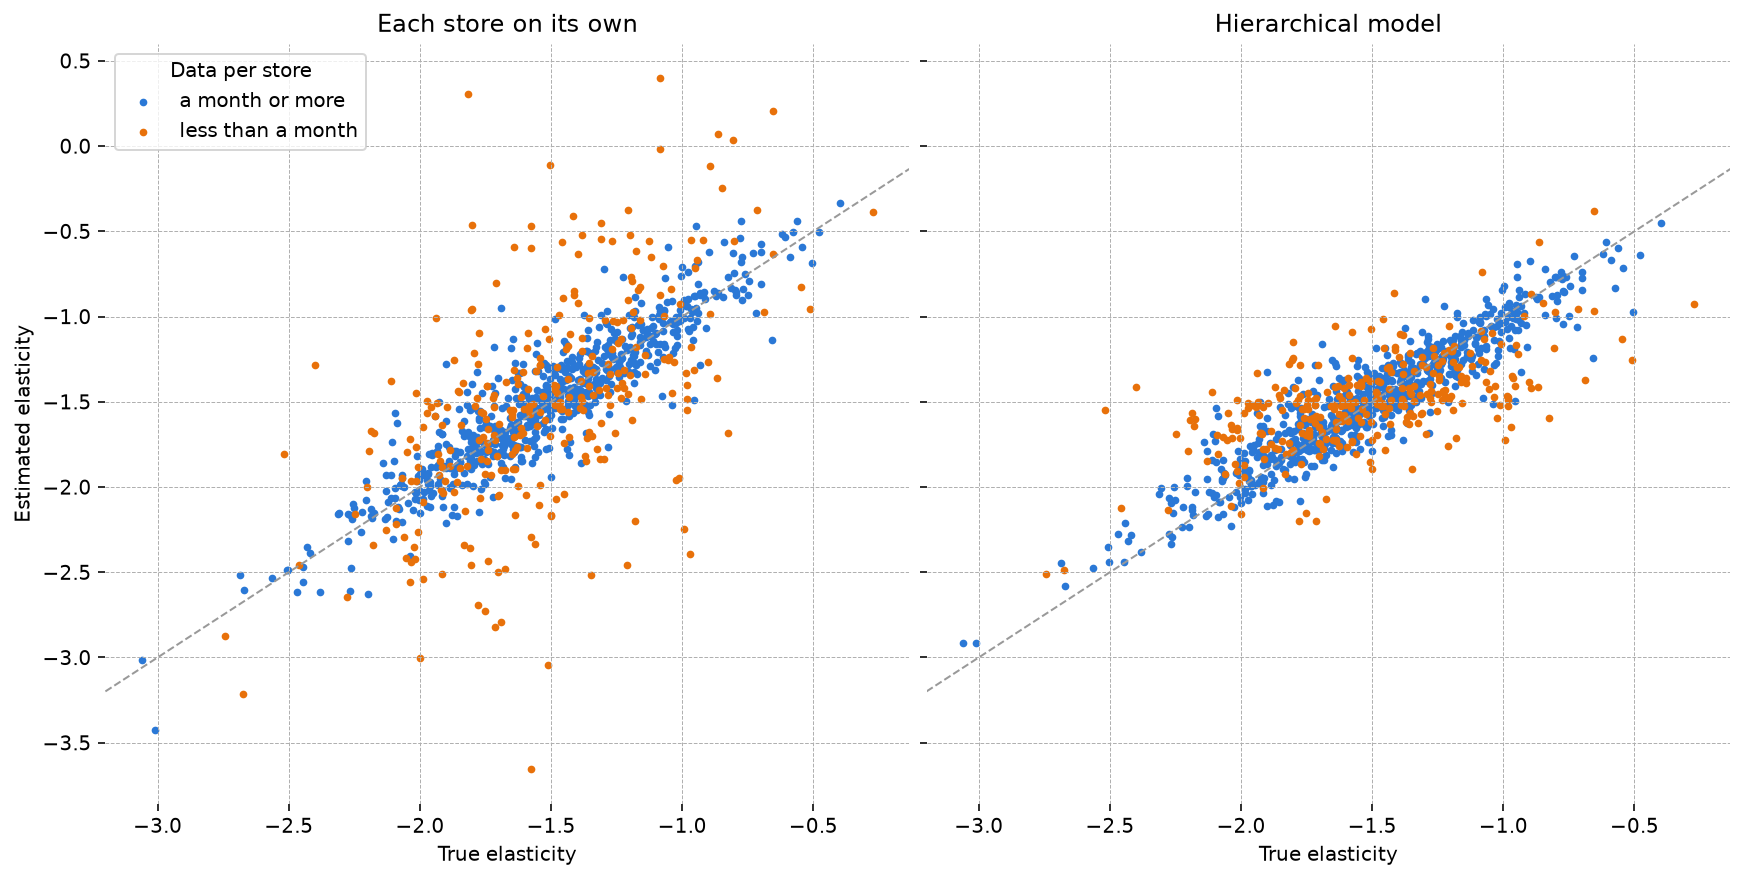

In [12]:
def own_estimate(df: pd.DataFrame) -> float:
    """Slope of a straight line through one store's own data."""
    return np.polyfit(df["log_price"], df["log_units"], 1)[0]


estimates = {
    "Each store on its own": sales_df.groupby("store")[["log_price", "log_units"]].apply(own_estimate),
    "Hierarchical model": idata.posterior["elasticity"].mean(("chain", "draw")).to_series(),
}
new = n_days < 30  # stores with less than a month of data

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)
for ax, (title, estimate) in zip(axes, estimates.items(), strict=True):
    ax.axline((true_mu_elasticity, true_mu_elasticity), slope=1, color="0.6", lw=1, ls="--")
    ax.scatter(true_elasticity[~new], estimate[~new], s=8, color="#2a78d6", label="a month or more")
    ax.scatter(true_elasticity[new], estimate[new], s=8, color="#e8710a", label="less than a month")
    ax.set(title=title, xlabel="True elasticity")
axes[0].set(ylabel="Estimated elasticity")
axes[0].legend(title="Data per store");

## Posterior predictive check

If the model describes the data well, sales simulated from it should look like the real sales. `sharded.sample_posterior_predictive` simulates them on the workers, each for its own rows, and puts the results back in the order of `sales_df`. The result holds one simulated value per row and draw, which adds up quickly with this many rows, so `num_draws=25` uses only 25 evenly spaced draws from each chain, that is 100 sets of simulated sales, plenty for a plot.

Each thin blue line is the distribution of one set of simulated sales, and the black line is the distribution of the real sales.

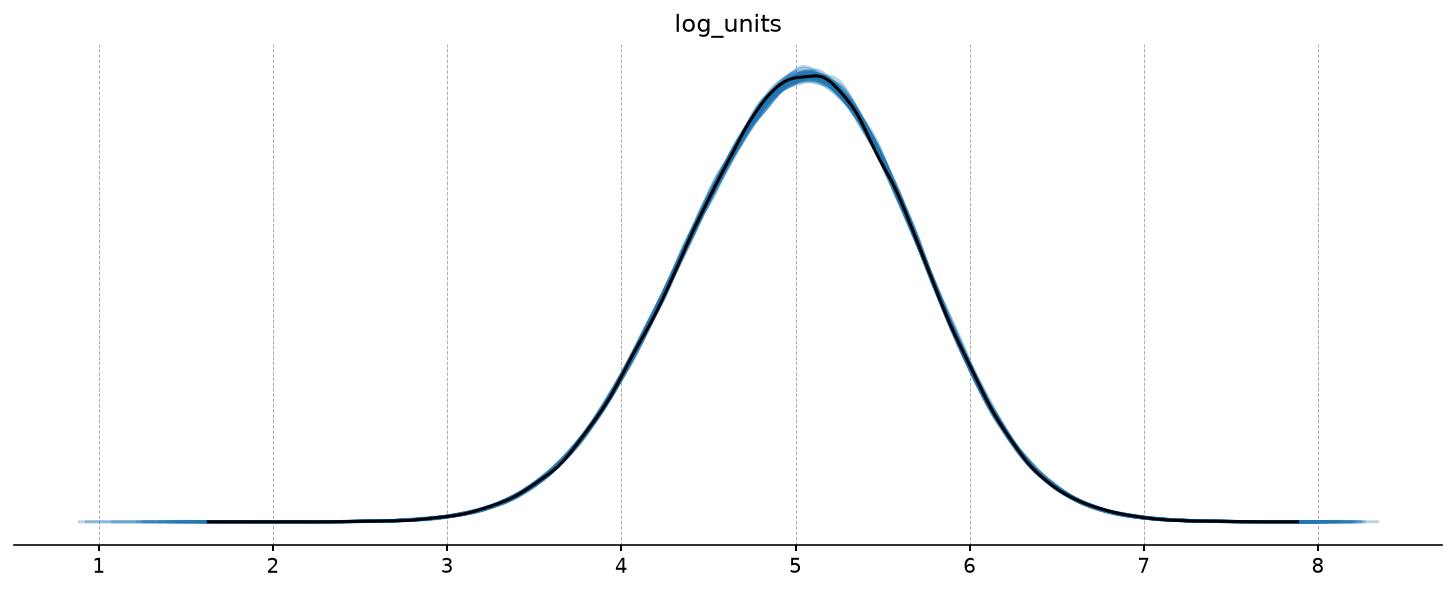

In [13]:
idata = sharded.sample_posterior_predictive(idata, num_draws=25, random_seed=42, extend_inferencedata=True)
az.plot_ppc_dist(idata, figure_kwargs={"figsize": (10, 4)});

## LOO cross-validation

LOO estimates how well the model predicts data it has not seen. The estimate, `elpd_loo`, is mainly useful for comparing models. `sharded.loo` computes it on the workers. Each worker computes the log-likelihood of its own rows under every posterior draw, runs PSIS-LOO on them, and sends back only one value per row. The result is the same as `az.loo` on all the data.

Together, the workers hold one value per row and draw, and about as much again while they compute. With all 4,000 draws, that is 150,000 rows × 4,000 draws × 8 bytes, about 5 GB, and twice that at the peak. Every 4th draw, 1,000 in all, is plenty for LOO.

In [14]:
%%time
elpd = sharded.loo(idata.isel(draw=slice(None, None, 4)))  # every 4th draw
elpd

CPU times: user 240 ms, sys: 34 ms, total: 274 ms
Wall time: 9.43 s


<timed exec>:1: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.67 for one or more observations. Importance sampling is unreliable for them; consider a more robust model.


Computed from 1000 posterior samples and 149874 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -33284.93   273.38
p_loo     1718.42        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                          Count   Pct.
(-Inf, 0.67]   (good)     149870  100.0%
   (0.67, 1]   (bad)           4    0.0%
    (1, Inf)   (very bad)      0    0.0%

Check two things, similar to the consensus tutorial:

- **Pareto *k*.** A handful of rows are above the threshold, and the warning above flags them. They belong to stores with only a few days or weeks of data. For such a store, one day is a big part of everything its parameters learn from, so leaving it out changes them too much for the shortcut that PSIS-LOO takes. A handful out of 150,000 hardly moves the total. If many rows were flagged, the estimate could not be trusted.

- **`p_loo`**, the effective number of parameters, should not be far above the actual number. Here it is below the model's 2,003 parameters because the hierarchical model pulls the elasticities toward each other, so each counts for less than a full parameter.

To compare this model with another, pass both LOO results to `az.compare`, as in the consensus tutorial.

## Shut down

The workers hold the data until you shut them down. `sharded.shutdown()` frees them. In a script, `with pmr.ShardedModel(...) as sharded:` does this for you at the end of the block.

In [15]:
sharded.shutdown()
ray.shutdown()

## Additional Features Not Shown in This Tutorial

- **More data than fits in memory.** Pass a Ray Dataset, such as `ray.data.read_parquet(...)`, instead of a DataFrame. Each worker then loads only its own shard, and the full data never have to fit on this machine.
